<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES_7_Planning_a_telescope_observation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Planning a telescope observation**

From past history, you know that:

$$p(\text{clear tomorrow} \mid \text{cloudy today}) = 0.5,$$

which means that

$$p(\text{cloudy tomorrow} \mid \text{cloudy today}) = 0.5.$$

We also have

$$p(\text{cloudy tomorrow} \mid \text{clear today}) = 0.1,$$

which means that

$$p(\text{clear tomorrow} \mid \text{clear today}) = 0.9.$$

* We can start with the sky conditions today and make predictions going forward more and more into the future.
* This will look like a big decision tree.
* After enough days, we'll reach equilibrium probabilities that have to do with the mean weather statistics (ignoring seasons) and we'll arrive at

$$p(\text{clear}) = 0.83,$$

and

$$p(\text{cloudy}) = 0.17.$$

You get the same answer for day $N$ as day $N+1$ and it doesn't matter whether it was clear or cloudy on the day that you started. The steps that we have taken in this process are, indeed, a **MARKOV CHAIN**.

In [127]:
import scipy as sc
import numpy as np
from scipy import stats as st
from matplotlib import pyplot as plt
import astroML.stats

#### Tasks

- Start off on a cloud day.
- Implement your weather forecast based on the above probabilities
- Run your simulator for N days (with $N\gtrsim 10^4$)
- Prepare a plot with the number of days on the x axis and the cumulative fraction of, say, sunny days over the number of days so far on the y axis. This is called a **trace-plot**, showing how our estimate of $p(\mathrm{clear})$ evolves as the chain samples.  


*  sunny = 1
*  cloudy = 0

In [128]:
# Transition probabilities
def weather(today,sunny_given_cloudy,cloudy_given_sunny):
    r = np.random.uniform(0, 1)
    if today == 0:
        return 1 if r < sunny_given_cloudy else 0
    else:
        return 0 if r < cloudy_given_sunny else 1

In [129]:
N = 10**4

sunny_given_cloudy= 0.5 #probability sunny tomorrow cloudy today
cloudy_given_sunny= 0.1 #probability cloudy tomorrow clear today

today= 0  #starting with a cloudy day
weather_days= []  #array storing the weather of the day
cumulative_sunny=[] #cumulative array sunny day
cumulative_cloudy=[]
weather_counter=0

for i in range (1,N+1):
  today= weather(today,sunny_given_cloudy,cloudy_given_sunny)
  weather_days.append(today)
  weather_counter= weather_counter + today
  cumulative_sunny.append(weather_counter/i)
  cumulative_cloudy.append(1-weather_counter/i)


- Prepare a histogram of the above plot. This reveals the distribution of $p(\mathrm{clear})$.
- Use a summary statistics to determine the most likely value and an error on our estimate.

**FULL TRACE**

Trace Plot

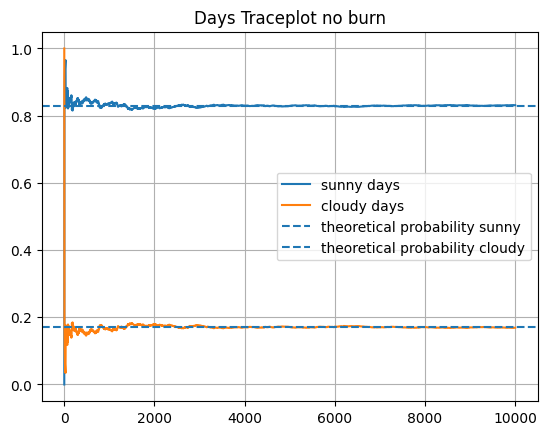

In [130]:
#plot

xgrid= np.linspace(1,N+1,N)
plt.plot(xgrid,cumulative_sunny,label='sunny days')
plt.plot(xgrid,cumulative_cloudy,label='cloudy days')
plt.axhline(y=0.83, linestyle='--', label='theoretical probability sunny ')
plt.axhline(y=0.17, linestyle='--', label='theoretical probability cloudy')
plt.title('Days Traceplot no burn')
plt.legend()
plt.grid()
plt.show()

Histograms

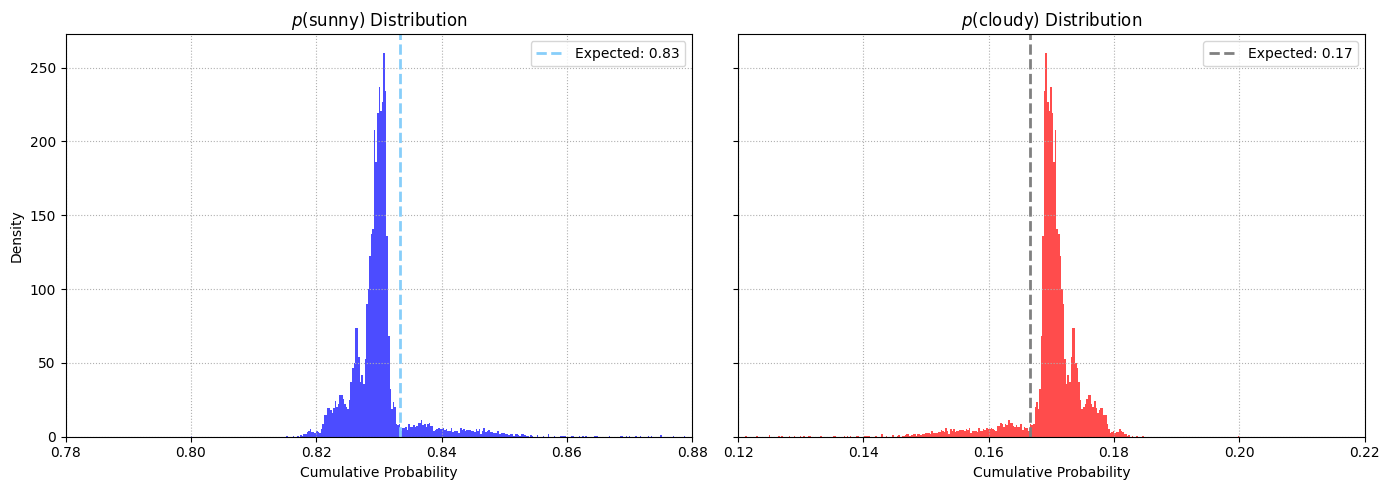

------SUMMARY STATISTIC--------
Full trace:
SUNNY
median = 0.8298
sigma_g  =  0.0020
CLOUDY
median = 0.1702
sigma_g  =  0.0020


In [151]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Histogram for p(clear)
axes[0].hist(cumulative_sunny, bins='fd', density=True, color='blue', alpha=0.7)
axes[0].axvline(5/6, color='lightskyblue', linestyle='--', linewidth=2, label='Expected: 0.83')
axes[0].set_title("$p(\\mathrm{sunny})$ Distribution")
axes[0].set_xlabel("Cumulative Probability")
axes[0].set_ylabel("Density")
axes[0].set_xlim(0.78, 0.88)
axes[0].grid(True, linestyle=":")
axes[0].legend(loc="upper right")

# Histogram for p(cloudy)
axes[1].hist(cumulative_cloudy, bins='fd', density=True, color='red', alpha=0.7)
axes[1].axvline(1/6, color='gray', linestyle='--', linewidth=2, label='Expected: 0.17')
axes[1].set_title("$p(\\mathrm{cloudy})$ Distribution")
axes[1].set_xlabel("Cumulative Probability")
axes[1].set_xlim(0.12, 0.22)
axes[1].grid(True, linestyle=":")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

median_sunny = np.median(cumulative_sunny)
error_sunny = astroML.stats.sigmaG(cumulative_sunny)
median_cloudy = np.median(cumulative_cloudy)
error_cloudy = astroML.stats.sigmaG(cumulative_cloudy)
print('------SUMMARY STATISTIC--------')
print(f"Full trace:")
print(f'SUNNY')
print(f"median = {median_sunny:.4f}")
print(f"sigma_g  =  {error_sunny:.4f}")
print(f'CLOUDY')
print(f"median = {median_cloudy:.4f}")
print(f"sigma_g  =  {error_cloudy:.4f}")


#### Tasks

- In the above example, experiment with chopping off different numbers of initial points as burn-in.

**BURN**

Burn: 10%
median = 0.8296
sigma_g  =  0.0019
Burn: 25%
median = 0.8299
sigma_g  =  0.0014
Burn: 50%
median = 0.8299
sigma_g  =  0.0013


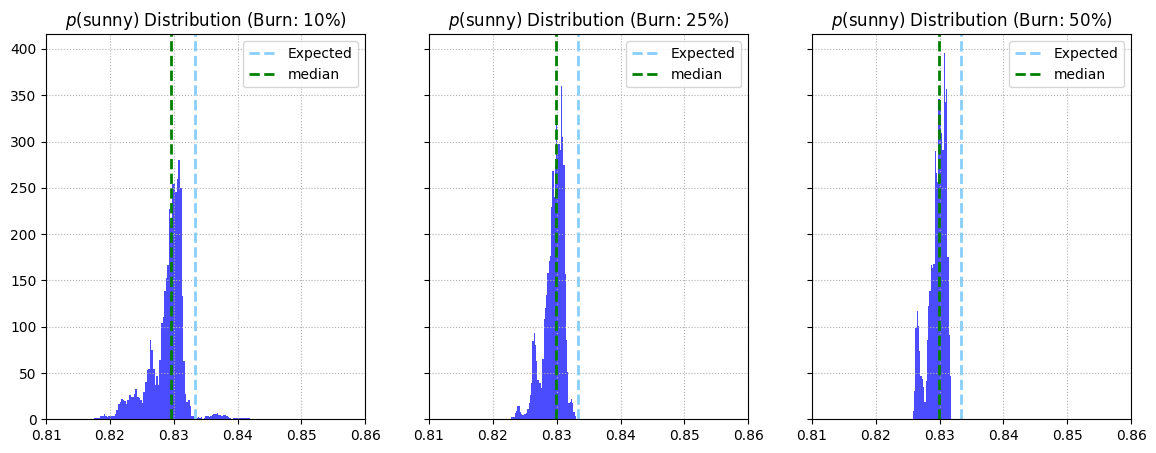

In [150]:
burn = [1000, 2500,5000]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
i=0
for burn in burn:
  #using robust estimator
  median_sunny = np.median(cumulative_sunny[burn:])
  error_sunny = astroML.stats.sigmaG(cumulative_sunny[burn:]) #interquartile range

  axes[i].hist(cumulative_sunny[burn:], bins='fd', density=True, color='blue', alpha=0.7)
  axes[i].axvline(5/6, color='lightskyblue', linestyle='--', linewidth=2, label='Expected') #using more accurate expected values
  axes[i].axvline(median_sunny, color='green', linestyle='--', linewidth=2, label='median')
  axes[i].set_title(f"$p(\\mathrm{{sunny}})$ Distribution (Burn: {int(burn/N*100)}%)")
  axes[i].set_xlim(0.81, 0.86)
  axes[i].grid(True, linestyle=":")
  axes[i].legend(loc="upper right")

  print(f"Burn: {int(burn/N*100)}%")
  print(f"median = {median_sunny:.4f}")
  print(f"sigma_g  =  {error_sunny:.4f}")
  i=i+1
plt.show()



**burn-in cut vs $\sigma_g$ **




<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3159/1093126161.py:9: SyntaxWarning: invalid escape sequence '\s'
  plt.title('burn vs $\sigma_g $')


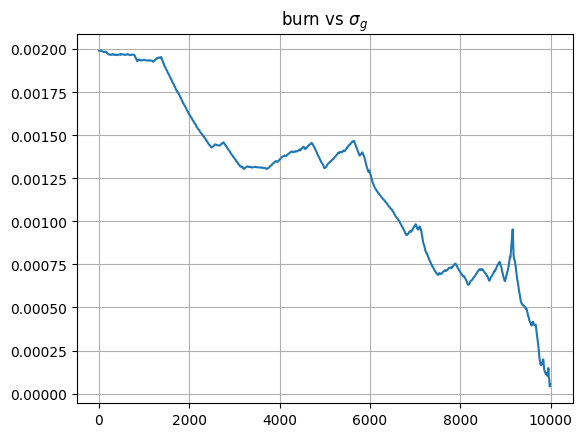

In [133]:
burns = np.arange(10, N-1, 10)
error_sunny_array=[] #storing the sigmas


for burn in burns:
  error_sunny_array.append(astroML.stats.sigmaG(cumulative_sunny[burn:]))
#plot
plt.plot(burns,error_sunny_array)
plt.title('burn vs $\sigma_g $')
plt.grid()

